In [2]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\sebas\Downloads\archive\dirty_cafe_sales.csv")

In [3]:


def audit_report(df: pd.DataFrame) -> pd.DataFrame:
    metrics = []
    for col in df.columns:
        metrics.append({
            'columna': col,
            'dtype': df[col].dtype,
            '%_nulos': round(df[col].isna().mean() * 100, 2),
            'unicos': df[col].nunique()
        })
    return pd.DataFrame(metrics)

# For saving the initial state
df_raw = pd.read_csv(r"C:\Users\sebas\Downloads\archive\dirty_cafe_sales.csv") 
df_audit_before = audit_report(df_raw)
print(df_audit_before)

            columna dtype  %_nulos  unicos
0    Transaction ID   str     0.00   10000
1              Item   str     3.33      10
2          Quantity   str     1.38       7
3    Price Per Unit   str     1.79       8
4       Total Spent   str     1.73      19
5    Payment Method   str    25.79       5
6          Location   str    32.65       4
7  Transaction Date   str     1.59     367


In [4]:
df.head(5)
df.sample(10)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9524,TXN_5336876,Smoothie,ERROR,4.0,12.0,Credit Card,NaN,2023-07-07
819,TXN_5489408,Cookie,1,1.0,1.0,UNKNOWN,In-store,2023-05-02
6199,TXN_1123346,Tea,3,1.5,4.5,NaN,NaN,2023-07-31
8355,TXN_4235472,Salad,5,5.0,25.0,NaN,Takeaway,2023-12-22
6441,TXN_4439660,Coffee,3,2.0,6.0,NaN,NaN,2023-02-06
70,TXN_2621580,Tea,2,1.5,3.0,Cash,In-store,2023-03-22
6832,TXN_8036247,Coffee,1,2.0,2.0,Credit Card,Takeaway,2023-09-29
6431,TXN_9110336,Cookie,5,1.0,5.0,Digital Wallet,ERROR,2023-04-06
1134,TXN_1544070,Coffee,5,2.0,10.0,UNKNOWN,Takeaway,2023-09-05
6463,TXN_9388222,Cookie,1,1.0,1.0,Digital Wallet,In-store,2023-04-21


In [5]:
df.dtypes

Transaction ID      str
Item                str
Quantity            str
Price Per Unit      str
Total Spent         str
Payment Method      str
Location            str
Transaction Date    str
dtype: object

In [6]:

def clean_placeholders(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy() # Copia de seguridad en memoria
    placeholders = ['UNKNOWN', 'ERROR', 'N/A', '', 'null', 'None', 'nan']
    return df.replace(placeholders, np.nan)
def convert_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
    df['Price Per Unit'] = pd.to_numeric(df['Price Per Unit'], errors='coerce')
    df['Total Spent'] = pd.to_numeric(df['Total Spent'], errors='coerce')
    df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], errors='coerce')
    return df


In [7]:
def recover_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # 1. Initial algebraic recovery (where 2 of the 3 variables exist)
    df['Quantity'] = df['Quantity'].fillna(df['Total Spent'] / df['Price Per Unit'])
    df['Price Per Unit'] = df['Price Per Unit'].fillna(df['Total Spent'] / df['Quantity'])

    # 2. Impute missing item if it doesn't exist (Global mode)
    item_mode = df['Item'].mode()[0] if not df['Item'].mode().empty else 'Coffee'
    df['Item'] = df['Item'].fillna(item_mode)

    # 3. Impute Unit Price by Catalog (Item -> Median Price)
    item_to_price = df.groupby('Item')['Price Per Unit'].median().to_dict()
    df['Price Per Unit'] = df['Price Per Unit'].fillna(df['Item'].map(item_to_price))

    # 4. Impute Missing Amount (Mode by Item)
    quantity_mode = df.groupby('Item')['Quantity'].transform(
        lambda x: x.mode()[0] if not x.mode().empty else 1.0
    )
    df['Quantity'] = df['Quantity'].fillna(quantity_mode)

    # =========================================================================
    # KEY LINE: TOTAL ACCOUNTING RECALCULATION (Zero Nulls, 100% Accuracy)
    # This is where the discrepancy is resolved: multiplication is recalculated
    # once Quantity and Price Per Unit are 100% clean and imputed.
    # =========================================================================
    df['Total Spent'] = df['Quantity'] * df['Price Per Unit']

    # 5. Temporal Sequence (Forward Fill of dates sorted by ID)
    df = df.sort_values(by='Transaction ID')
    df['Transaction Date'] = df['Transaction Date'].ffill()

    return df

In [8]:
def flag_outliers(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    # Rule: Out-of-range quantities (e.g., less than 1 or greater than 20)
    df['is_outlier_quantity'] = (df['Quantity'] <= 0) | (df['Quantity'] > 20)
    return df

In [9]:
# 1. Re-execute Pipeline
df_clean = (
    df_raw
    .pipe(clean_placeholders)
    .pipe(convert_dtypes)
    .pipe(recover_data)
    .pipe(flag_outliers)
)

# 2. Confirm that the filter returns 0 rows
print("Rows with null Total Spent:", df_clean['Total Spent'].isna().sum())

# 3. Final Validations (Quality Circuit Breakers)
assert df_clean['Total Spent'].isna().sum() == 0, "ERROR: Nulls still exist in Total Spent"
assert df_clean['Quantity'].isna().sum() == 0, "ERROR: Nulls still exist in Quantity"
assert df_clean['Price Per Unit'].isna().sum() == 0, "ERROR: Nulls still exist in Price Per Unit"
assert df_clean['Transaction ID'].is_unique, "ERROR: Duplicate IDs found."
assert df_clean[['Quantity', 'Price Per Unit', 'Total Spent', 'Transaction Date']].isna().sum().sum() == 0, "ERROR: Residual nulls exist."
assert np.isclose(df_clean['Total Spent'], df_clean['Quantity'] * df_clean['Price Per Unit']).all(), "ERROR: Accounting discrepancy Total != Quantity * Price."

# Validate exact accounting balance (with floating-point tolerance of 0.01)
math_diff = np.abs(df_clean['Total Spent'] - (df_clean['Quantity'] * df_clean['Price Per Unit']))
assert (math_diff < 1e-2).all(), "ACCOUNTING ERROR: Discrepancy in Total Spent calculation."

print("BUG RESOLVED: Dataset 100% clean and validated.")

Rows with null Total Spent: 0
BUG RESOLVED: Dataset 100% clean and validated.


In [10]:
df.columns

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='str')

In [11]:
df['Transaction ID'].duplicated().sum()


np.int64(0)

In [12]:
# Display rows where Total Spent could not be calculated
df[df['Total Spent'].isna()]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
25,TXN_7958992,Smoothie,3,4.0,NaN,UNKNOWN,UNKNOWN,2023-12-13
65,TXN_4987129,Sandwich,3,NaN,NaN,NaN,In-store,2023-10-20
146,TXN_7623634,Cake,2,3.0,NaN,Credit Card,In-store,2023-07-11
171,TXN_8989148,Tea,2,1.5,NaN,NaN,NaN,2023-11-25
238,TXN_5526852,Sandwich,5,4.0,NaN,Digital Wallet,In-store,2023-09-28
...,...,...,...,...,...,...,...,...
9827,TXN_3392953,Coffee,1,2.0,NaN,Digital Wallet,Takeaway,2023-01-06
9838,TXN_6744733,Sandwich,1,4.0,NaN,Cash,Takeaway,UNKNOWN
9890,TXN_2749289,Smoothie,2,4.0,NaN,Digital Wallet,Takeaway,2023-05-05
9988,TXN_9594133,Cake,5,3.0,NaN,ERROR,NaN,NaN


In [13]:
df_clean.to_csv('clean_cafe_sales_v1.csv', index=False, encoding='utf-8')

In [36]:
import os

filepath = r'C:\Users\sebas\Desktop\clean_cafe_sales_v1.csv'
df_clean.to_csv(filepath, index=False)

# Opens Windows Explorer highlighting the newly created CSV
os.system(f'explorer /select,"{filepath}"')

1

In [15]:
import sqlite3
import pandas as pd
df_clean = pd.read_csv('clean_cafe_sales_v1.csv')
# conectar a SQL e ingestar el dataframe la tabla sales
conn = sqlite3.connect('cafe_transactions.db')
df_clean.to_sql('Sales', conn, if_exists='replace',index=False)
# Verificacion de conteo exacto
total_rows = pd.read_sql_query('SELECT COUNT(1) AS TOTAL FROM sales',conn)
conteo_exacto = total_rows.iloc[0, 0]
print(f'VERIFICACION: {conteo_exacto}Registros ingestados en SQLite:')
def q(sql):
    return pd.read_sql_query(sql,conn)

VERIFICACION: 10000Registros ingestados en SQLite:


In [16]:
#general indicators 
q('''
SELECT COUNT(*) AS transactions,
        ROUND(SUM("Total Spent"),2) AS revenue,
        ROUND(AVG("Total Spent"),2) AS avg_ticket
FROM sales;
''')

,transactions,revenue,avg_ticket
0,10000,89410.5,8.94


In [17]:
# sales by payment method
q('''
SELECT 'Payment Method', COUNT(*) AS n, ROUND(SUM('Total Spent'),2) AS revenue
FROM sales
GROUP BY 'Payment Method'
ORDER BY revenue DESC;
''')


,'Payment Method',n,revenue
0,Payment Method,10000,0.0


In [18]:
# ranking articles 
q("""
WITH item_rev AS (
    SELECT 'Item', SUM("Total Spent") AS revenue
    FROM sales
    GROUP BY item
)
SELECT 'Item', ROUND(revenue,2) AS revenue,
        RANK() OVER (ORDER BY revenue DESC) AS rnk
FROM item_rev;
""")


,'Item',revenue,rnk
0,Item,19034.5,1
1,Item,17415.0,2
2,Item,13796.0,3
3,Item,13400.0,4
4,Item,10446.0,5
5,Item,7128.0,6
6,Item,4953.0,7
7,Item,3238.0,8


In [19]:
# sales by each month acumulated 
q("""
WITH monthly AS(
    SELECT strftime('%Y-%m','Transaction Date') AS month, SUM('Total Spent') AS revenue
    FROM sales
    GROUP BY month
)
SELECT month, ROUND(revenue,2) AS revenue,
        ROUND(SUM(revenue) OVER (ORDER BY month),2) AS running_total
FROM monthly;
""")

,month,revenue,running_total
0,None,0.0,0.0


In [20]:
#partificpation by ubication and payment method 
q("""
SELECT 
    "Location", 
    "Payment Method",
    ROUND(SUM("Total Spent"), 2) AS revenue,
    ROUND(100.0 * SUM("Total Spent") / SUM("Total Spent") OVER (PARTITION BY "Location"), 1) AS pct_of_location
FROM sales
GROUP BY "Location", "Payment Method"
ORDER BY "Location", revenue DESC;
""")

,Location,Payment Method,revenue,pct_of_location
0,NaN,NaN,11194.0,24334.8
1,NaN,Credit Card,8542.5,18570.7
2,NaN,Cash,8128.5,17670.7
3,NaN,Digital Wallet,7580.0,16478.3
4,In-store,NaN,8281.5,30114.5
5,In-store,Digital Wallet,6557.5,23845.5
6,In-store,Cash,6440.0,23418.2
7,In-store,Credit Card,6031.0,21930.9
8,Takeaway,NaN,8491.0,21227.5
9,Takeaway,Digital Wallet,6327.5,15818.8


In [21]:
df_clean.columns

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date',
       'is_outlier_quantity'],
      dtype='str')

In [22]:
import os 
import pandas as pd
import matplotlib.pyplot as plt

clean = df_clean.copy()

os.makedirs('docs/figures',exist_ok = True)
plt.rcParams.update({
    "figure.figsize": (8,5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    
})

def save(name):
    plt.tight_layout()
    plt.savefig(f'docs/figures/{name}.png',dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
# return back into datetime 
clean['Transaction Date'] = pd.to_datetime(clean['Transaction Date'])

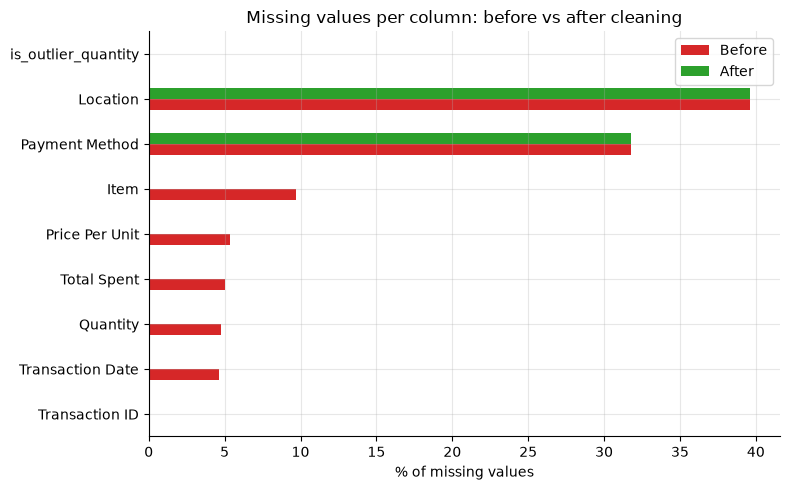

In [23]:
raw = df_raw.copy()
raw_std = raw.pipe(convert_dtypes)
before = raw_std.pipe(clean_placeholders).isna().mean() * 100
after = clean.isna().mean() * 100

nulls = pd.DataFrame({"Before": before , "After": after}).sort_values("Before")
ax = nulls.plot.barh(color=["#d62728", "#2ca02c"])
ax.set_xlabel("% of missing values")
ax.set_title("Missing values per column: before vs after cleaning")
save("nulls_before_after")

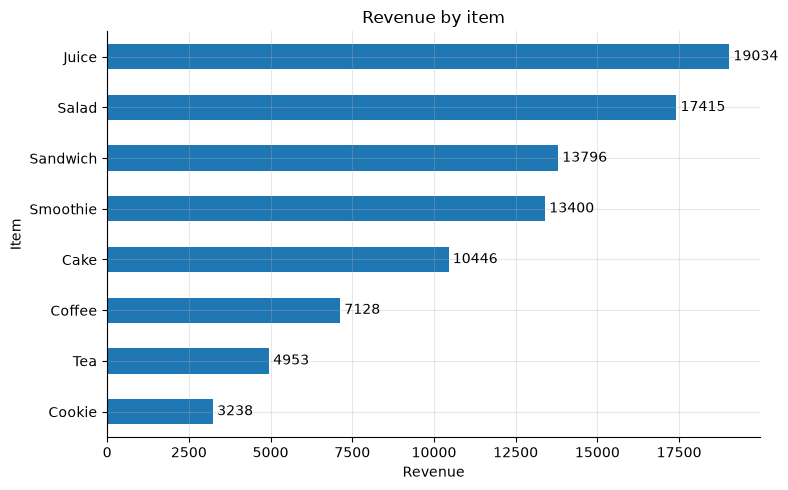

In [24]:
rev_item = clean.groupby("Item")['Total Spent'].sum().sort_values()
ax = rev_item.plot.barh(color="#1f77b4")
ax.bar_label(ax.containers[0], fmt='%.0f', padding = 3)
ax.set_xlabel('Revenue')
ax.set_title('Revenue by item')
save('revenue_by_item')

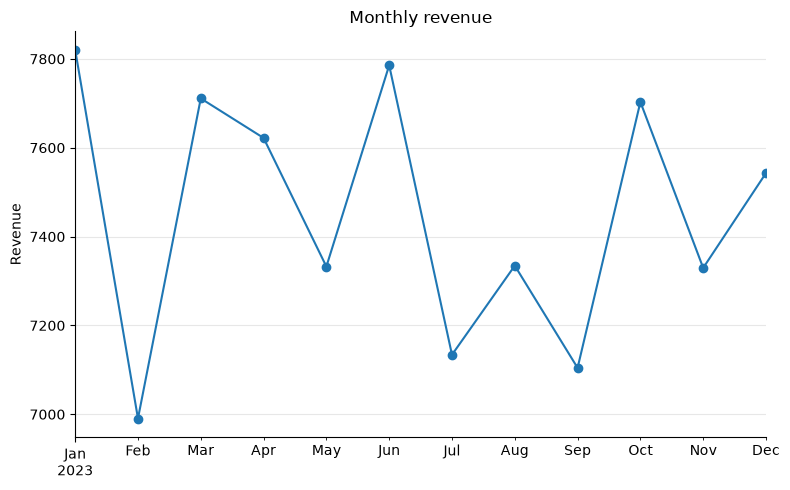

In [25]:
monthly = clean.set_index('Transaction Date')['Total Spent'].resample('ME').sum()
ax = monthly.plot(marker='o', color = "#1f77b4" )
ax.set_ylabel('Revenue')
ax.set_xlabel('')
ax.set_title('Monthly revenue')
save("revenue_by_month")

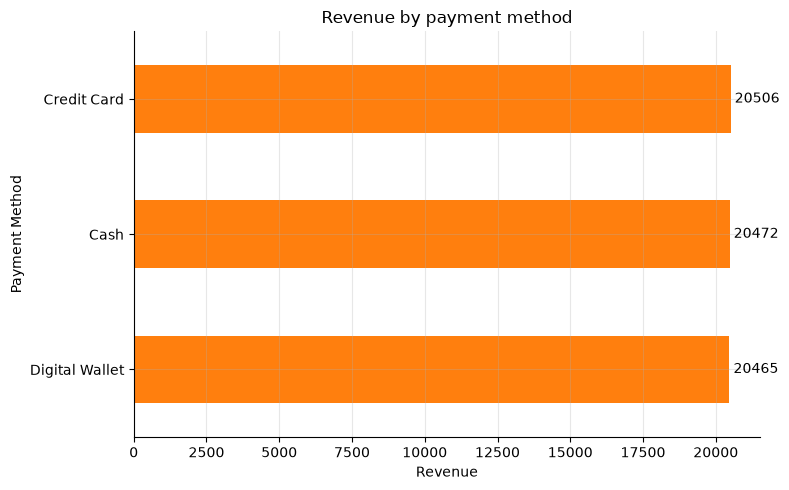

In [26]:
rev_pay = clean.groupby("Payment Method")['Total Spent'].sum().sort_values()
ax = rev_pay.plot.barh(color="#ff7f0e")
ax.bar_label(ax.containers[0], fmt="%.0f", padding= 3)
ax.set_xlabel('Revenue')
ax.set_title("Revenue by payment method")
save("revenue_by_payment")

## Results
![Missing values before vs after](docs/figures/nulls_before_after.png)
![Revenue by item](docs/figures/revenue_by_item.png)
![Monthly revenue](docs/figures/revenue_by_month.png)

In [27]:
# Definición de cadenas ruidosas
placeholders = ['UNKNOWN', 'ERROR', 'N/A', '', 'NULL', 'NONE', 'NAN', 'null', 'none']

# A. Conteo de celdas con texto basura convertidas
placeholders_converted = df_raw.isin(placeholders).sum().sum()

# B. Filas de Item recuperadas
raw_item_dirty = df_raw['Item'].isin(placeholders) | df_raw['Item'].isna()
items_recovered = raw_item_dirty.sum() - df_clean['Item'].isna().sum()

# C. Filas de Total Spent recuperadas
raw_total_dirty = df_raw['Total Spent'].isin(placeholders) | df_raw['Total Spent'].isna()
totals_recovered = raw_total_dirty.sum() - df_clean['Total Spent'].isna().sum()

# D. Total global de nulos/errores eliminados
raw_with_nans = df_raw.replace(placeholders, np.nan)
total_nulls_before = raw_with_nans.isna().sum().sum()
total_nulls_after = df_clean.isna().sum().sum()
total_nulls_removed = total_nulls_before - total_nulls_after

print("=" * 60)
print("VALORES EXACTOS PARA PEGAR EN EL README.MD")
print("=" * 60)
print(f"Text Placeholders Converted : {placeholders_converted} celdas")
print(f"Missing Item Recovered     : {items_recovered} filas")
print(f"Missing Total Recovered    : {totals_recovered} filas")
print(f"Total Nulls Removed        : {total_nulls_removed} celdas limpiadas")
print(f'Rows recovered: {items_recovered + totals_recovered}')
print("=" * 60)

VALORES EXACTOS PARA PEGAR EN EL README.MD
Text Placeholders Converted : 3256 celdas
Missing Item Recovered     : 969 filas
Missing Total Recovered    : 502 filas
Total Nulls Removed        : 2943 celdas limpiadas
Rows recovered: 1471


In [28]:
# 1. Nulos restantes columna por columna
print("--- Nulos por columna ---")
print(clean.isna().sum())

# 2. Conteo global absoluto en todo el DataFrame
total_remaining = clean.isna().sum().sum()
print(f"\nTotal global de nulos restantes: {total_remaining}")

--- Nulos por columna ---
Transaction ID            0
Item                      0
Quantity                  0
Price Per Unit            0
Total Spent               0
Payment Method         3178
Location               3961
Transaction Date          0
is_outlier_quantity       0
dtype: int64

Total global de nulos restantes: 7139


In [29]:
import pandas as pd

# Cargar datasets

clean.columns = clean.columns.str.lower().str.replace(' ', '_')

# 1. Total de nulos antes vs después (X e Y)
placeholders = ['UNKNOWN', 'ERROR', 'N/A', '', 'NULL', 'NONE', 'NAN', 'null', 'none']
raw_nans = raw.replace(placeholders, pd.NA)
X_nulls_before = raw_nans.isna().sum().sum()
Y_nulls_after = clean.isna().sum().sum()

# 2. Ventas por Producto (Z, second_item, N)
item_rev = clean.groupby('item')['total_spent'].sum().sort_values(ascending=False)
total_rev = clean['total_spent'].sum()

juice_rev = item_rev.get('Juice', 0)
Z_pct = round((juice_rev / total_rev) * 100, 1)

second_item = item_rev.index[1]
N_rev = round(item_rev.iloc[1], 2)

print(f"X (Nulos Antes)   : {X_nulls_before}")
print(f"Y (Nulos Después) : {Y_nulls_after}")
print(f"Z (% Juice)       : {Z_pct}%")
print(f"Second Item       : {second_item}")
print(f"N (Ventas 2do)    : {N_rev}")

X (Nulos Antes)   : 10082
Y (Nulos Después) : 7139
Z (% Juice)       : 21.3%
Second Item       : Salad
N (Ventas 2do)    : 17415.0


In [30]:
before_counts = raw_std.pipe(clean_placeholders).isna().sum()
after_counts = clean.isna().sum()
print((before_counts - after_counts)[lambda s: s > 0])

Series([], dtype: float64)


In [31]:
import pandas as pd

# 1. Ingest raw dataset with your exact local Windows path
df_raw = pd.read_csv(r"C:\Users\sebas\Downloads\archive\dirty_cafe_sales.csv")

# 2. Execute your exact pipeline chain
df_clean = (
    df_raw
    .pipe(clean_placeholders)
    .pipe(convert_dtypes)
    .pipe(recover_data)
    .pipe(flag_outliers)
)

# 3. Build Data Quality Audit (Bronze vs. Gold Layer)
data_quality_audit = pd.DataFrame({
    "raw_null_count": df_raw.pipe(clean_placeholders).isna().sum(),
    "clean_null_count": df_clean.isna().sum(),
})

# 4. Calculate exact recovered records per column
data_quality_audit["recovered_records"] = (
    data_quality_audit["raw_null_count"] - data_quality_audit["clean_null_count"]
)

# 5. Output telemetry metrics
print("=== DATA QUALITY AUDIT BY COLUMN ===")
print(data_quality_audit)

print("\n=== TOTAL DATASET METRICS ===")
print(data_quality_audit.sum())

=== DATA QUALITY AUDIT BY COLUMN ===
                     raw_null_count  clean_null_count  recovered_records
Item                          969.0                 0              969.0
Location                     3961.0              3961                0.0
Payment Method               3178.0              3178                0.0
Price Per Unit                533.0                 0              533.0
Quantity                      479.0                 0              479.0
Total Spent                   502.0                 0              502.0
Transaction Date              460.0                 0              460.0
Transaction ID                  0.0                 0                0.0
is_outlier_quantity             NaN                 0                NaN

=== TOTAL DATASET METRICS ===
raw_null_count       10082.0
clean_null_count      7139.0
recovered_records     2943.0
dtype: float64


<Axes: title={'center': 'Monthly revenue (original dates only)'}, xlabel='transaction_date'>

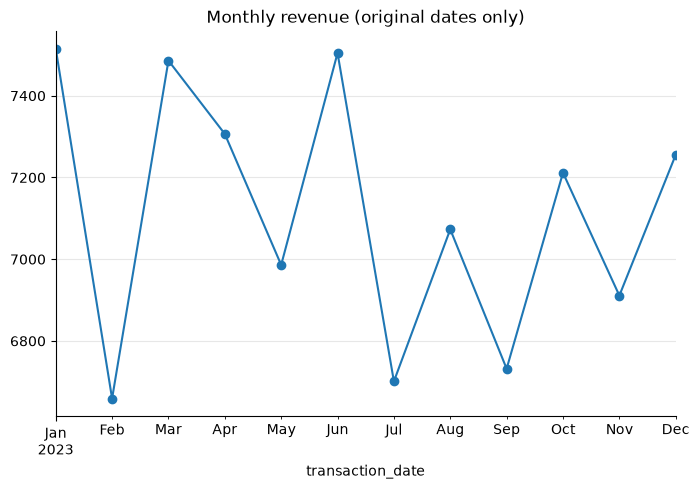

In [32]:
orig_dates = pd.to_datetime(raw["Transaction Date"], errors="coerce")
mask = orig_dates.notna()
monthly_orig = (clean.loc[mask.values]
                .set_index("transaction_date")["total_spent"]
                .resample("ME").sum())
monthly_orig.plot(marker="o", title="Monthly revenue (original dates only)")

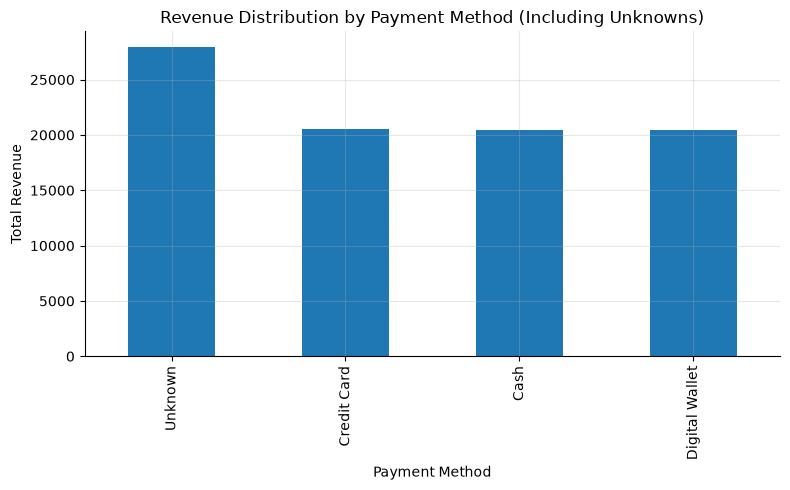

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# A. Trabajar con una copia para visualización
clean_payment = clean.copy()
clean_payment["payment_method"] = clean_payment["payment_method"].fillna("Unknown")

# B. Agrupar y calcular ingresos por canal
payment_rev = clean_payment.groupby("payment_method")["total_spent"].sum().sort_values(ascending=False)

# C. Graficar y exportar con el helper save()
ax = payment_rev.plot(kind="bar", color="#1f77b4")
ax.set_ylabel("Total Revenue")
ax.set_xlabel("Payment Method")
ax.set_title("Revenue Distribution by Payment Method (Including Unknowns)")

save("revenue_by_payment")

In [34]:
%%writefile requirements.txt
pandas
numpy
matplotlib

Overwriting requirements.txt


In [35]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
